In [19]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import shap
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# 数据导入
data = pd.read_csv('diabetes.csv')

# 特征和目标变量分离
X = data.drop(['Diabetes'], axis=1)
y = data['Diabetes']
original_X = X.copy()

# 数据归一化
scaler = MinMaxScaler()
X = scaler.fit_transform(X)
# 数据集划分
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 数据标准化
# scaler = MinMaxScaler()
# x_train_scaled = scaler.fit_transform(x_train)
# x_test_scaled = scaler.transform(x_test)

# 构建前馈神经网络模型
model = Sequential([
    Dense(64, input_dim=x_train.shape[1], activation='relu'),
    Dense(64, input_dim=x_train.shape[1], activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

# 编译模型
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 训练模型
model.fit(x_train, y_train, epochs=10, batch_size=10, validation_split=0.2)

# 预测
y_pred = model.predict(x_test)

# # 使用SHAP解释模型
# explainer = shap.KernelExplainer(model.predict, x_train_scaled)
# shap_values = explainer.shap_values(x_test_scaled)

# # 可视化第一个样本的SHAP值
# shap.initjs()
# shap.force_plot(explainer.expected_value[0], shap_values[0][0], x_test.iloc[0])


Epoch 1/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 711us/step - accuracy: 0.7800 - loss: 0.5252 - val_accuracy: 0.9434 - val_loss: 0.1799
Epoch 2/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 464us/step - accuracy: 0.9472 - loss: 0.1542 - val_accuracy: 0.9507 - val_loss: 0.1350
Epoch 3/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 460us/step - accuracy: 0.9492 - loss: 0.1329 - val_accuracy: 0.9376 - val_loss: 0.1594
Epoch 4/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 465us/step - accuracy: 0.9472 - loss: 0.1278 - val_accuracy: 0.9521 - val_loss: 0.1253
Epoch 5/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 459us/step - accuracy: 0.9629 - loss: 0.1007 - val_accuracy: 0.9376 - val_loss: 0.1580
Epoch 6/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 470us/step - accuracy: 0.9593 - loss: 0.1100 - val_accuracy: 0.9579 - val_loss: 0.1213
Epoch 7/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 468us/step - accuracy: 0.9551 - loss: 0.1174 - val_accuracy: 0.9536 - val_loss: 0.1229
Epoch 8/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 465us/step - accuracy: 0.9534 - loss: 0.1104 - 

In [20]:
from sklearn.metrics import f1_score,mean_squared_error,mean_squared_log_error,make_scorer

f1 = f1_score(y_test, y_pred.round())
f1

0.8798283261802575

In [21]:
import shap
import time
s = time.time()

explainer = shap.Explainer(model,x_test)
shap_values = explainer.shap_values(x_test)
feature_names = original_X.columns.tolist()

# Visualize SHAP values
# shap.summary_plot(shap_values[0], x_test)


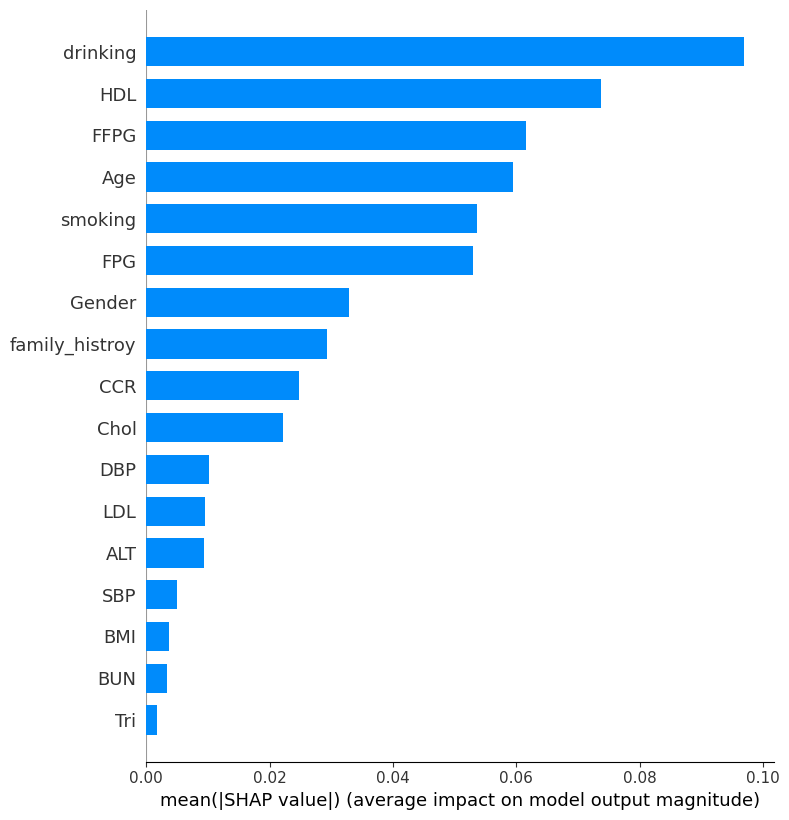

In [22]:
shap.summary_plot(shap_values, x_test, plot_type="bar", feature_names=feature_names)

In [23]:
# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(shap_values, columns=original_X.columns.tolist())
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)
shap_values_per_feature_sorted

Tri               0.001744
BUN               0.003334
BMI               0.003737
SBP               0.004961
ALT               0.009298
LDL               0.009465
DBP               0.010225
Chol              0.022145
CCR               0.024757
family_histroy    0.029326
Gender            0.032942
FPG               0.053054
smoking           0.053602
Age               0.059428
FFPG              0.061544
HDL               0.073769
drinking          0.096905
dtype: float64

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Assuming you have already calculated shap_values and x_test

# 最小-最大归一化到 [0, 1] 之间
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=True)
shap_values_per_feature_normalized

Tri               0.000000
BUN               0.016715
BMI               0.020946
SBP               0.033811
ALT               0.079382
LDL               0.081136
DBP               0.089123
Chol              0.214388
CCR               0.241833
family_histroy    0.289848
Gender            0.327847
FPG               0.539190
smoking           0.544953
Age               0.606179
FFPG              0.628411
HDL               0.756881
drinking          1.000000
dtype: float64

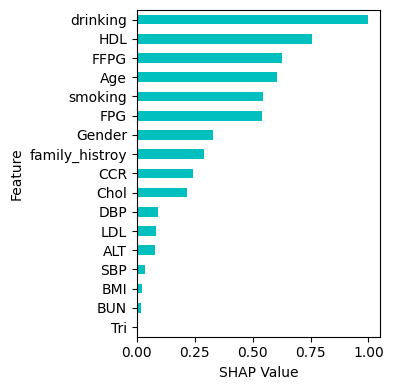

In [25]:
# Create a vertical figure for better spacing
plt.figure(figsize=(4, 4))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized.plot(kind='barh', color='c')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('shap_diabetes_nn_normalized.eps', format='eps', dpi=300)

plt.show()

In [33]:
import time
s = time.time()
import lime
import lime.lime_tabular


explainer = lime.lime_tabular.LimeTabularExplainer(x_train, feature_names=original_X.columns, class_names=['No Diabetes', 'Diabetes'], discretize_continuous=True)

# 定义预测函数
def predict_proba(X):
    proba = model.predict(X)
    return np.hstack((1-proba, proba))

# 选择一个样本进行解释
i = 10
exp = explainer.explain_instance(x_test[i], predict_proba, num_features=17)
# Extract feature values and their weights
feature_values = exp.as_list()

feature_values

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 560us/step


[('drinking <= 0.52', -0.5304152189058157),
 ('smoking <= 0.52', -0.2660179768571671),
 ('family_histroy <= 0.00', -0.2078525100817223),
 ('FPG <= 0.56', -0.10998966424112203),
 ('0.23 < HDL <= 0.28', -0.0862009291556942),
 ('Gender <= 0.00', 0.08212384370629036),
 ('0.34 < Age <= 0.54', 0.05174794076345545),
 ('0.08 < FFPG <= 0.11', -0.029838573698287945),
 ('0.22 < CCR <= 0.26', -0.02617819319767786),
 ('0.02 < ALT <= 0.04', -0.023640842798161914),
 ('BUN <= 0.16', -0.0179425603603581),
 ('SBP > 0.48', -0.011738341306783185),
 ('0.21 < BMI <= 0.28', -0.011440137005360526),
 ('0.31 < Chol <= 0.38', -0.010940202854689754),
 ('0.40 < LDL <= 0.50', -0.00431675044975306),
 ('Tri > 0.06', 0.003679448310961801),
 ('0.35 < DBP <= 0.43', 0.003005552081465658)]

In [34]:
# 提取特征值及其权重
feature_values = exp.as_map()[1]

# 根据权重的绝对值对特征进行排序
sorted_features = sorted(feature_values, key=lambda x: abs(x[1]), reverse=True)

# 提取特征名称和权重
features = [original_X.columns[i] for i, _ in sorted_features]
weights = [weight for _, weight in sorted_features]

# 打印排序后的特征及其权重（按绝对值排序）
# print("Sorted features by absolute weight (from largest to smallest):")
for feature, weight in zip(features, weights):
    print(f"Feature: {feature}, Weight: {abs(weight)}")


Feature: drinking, Weight: 0.5304152189058157
Feature: smoking, Weight: 0.2660179768571671
Feature: family_histroy, Weight: 0.2078525100817223
Feature: FPG, Weight: 0.10998966424112203
Feature: HDL, Weight: 0.0862009291556942
Feature: Gender, Weight: 0.08212384370629036
Feature: Age, Weight: 0.05174794076345545
Feature: FFPG, Weight: 0.029838573698287945
Feature: CCR, Weight: 0.02617819319767786
Feature: ALT, Weight: 0.023640842798161914
Feature: BUN, Weight: 0.0179425603603581
Feature: SBP, Weight: 0.011738341306783185
Feature: BMI, Weight: 0.011440137005360526
Feature: Chol, Weight: 0.010940202854689754
Feature: LDL, Weight: 0.00431675044975306
Feature: Tri, Weight: 0.003679448310961801
Feature: DBP, Weight: 0.003005552081465658


In [35]:
abs_weights = [abs(weight) for weight in weights]
# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]
normalized_weights

[1.0,
 0.4986871521702614,
 0.3884019783590343,
 0.20284822006360126,
 0.15774336783617612,
 0.15001297208148154,
 0.0924184590234731,
 0.05087699999582835,
 0.043936701531732986,
 0.03912573472713516,
 0.028321453356802247,
 0.016557886164467895,
 0.015992473127543084,
 0.015044568335276032,
 0.002486109851156913,
 0.0012777472084533853,
 0.0]

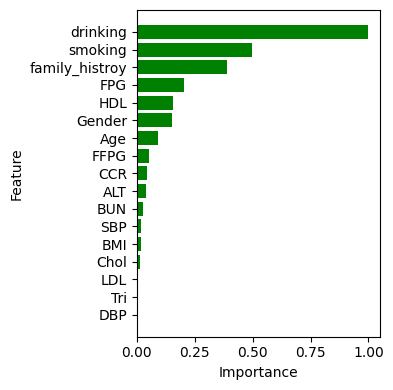

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# 计算绝对权重
abs_weights = [abs(weight) for weight in weights]

# 归一化处理
min_abs_weight = min(abs_weights)
max_abs_weight = max(abs_weights)
normalized_weights = [(w - min_abs_weight) / (max_abs_weight - min_abs_weight) for w in abs_weights]

# 绘制归一化后的特征权重条形图
plt.figure(figsize=(4, 4))
plt.barh(features, normalized_weights, color='g')  # 使用归一化后的权重
plt.xlabel('Importance')  # 修改x轴标签
plt.ylabel('Feature')
# plt.title('LIME Feature Weights (Normalized Absolute Values)')  # 修改标题
plt.gca().invert_yaxis()  # 反转y轴，使权重最大的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
plt.savefig('lime_diabetes_nn_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

In [37]:
from sklearn.inspection import permutation_importance
import numpy as np
result = permutation_importance(model, x_test, y_test, n_repeats=1, random_state=42, scoring='neg_mean_squared_error')

# 打印特征重要性
feature_names = original_X.columns.tolist()
importances = result.importances_mean
std = result.importances_std
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for f in range(x_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({importances[indices[f]]:.6f})")

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 506us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 401us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 392us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 376us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 419us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 434us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 426us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 400us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 399us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 401us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 396us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 422us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 390us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 394us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 392us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 400us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 437us/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 426us/step
Feature ranking:
1. feature drinking (0.092658)
2. feature HDL (0.062047)
3. feature smoking (0.042782)
4. feature FFPG (0.021258)
5. feature FPG (0.008123)
6. feature Age (0.005445)
7. feature Gender (0.005436)
8. feature Chol (0.002341)
9. feature family_histr

In [38]:
# 归一化处理
min_importance = np.min(importances)
max_importance = np.max(importances)
normalized_importances = (importances - min_importance) / (max_importance - min_importance)

# 按归一化后的重要性排序
indices = np.argsort(normalized_importances)[::-1]

# 打印归一化后的特征重要性
print("Feature ranking (normalized importance):")
for f in range(x_test.shape[1]):
    print(f"{f + 1}. feature {feature_names[indices[f]]} ({normalized_importances[indices[f]]:.6f})")

Feature ranking (normalized importance):
1. feature drinking (1.000000)
2. feature HDL (0.672094)
3. feature smoking (0.465733)
4. feature FFPG (0.235161)
5. feature FPG (0.094459)
6. feature Age (0.065782)
7. feature Gender (0.065686)
8. feature Chol (0.032528)
9. feature family_histroy (0.022245)
10. feature LDL (0.017172)
11. feature CCR (0.014762)
12. feature BUN (0.012207)
13. feature BMI (0.008619)
14. feature Tri (0.006574)
15. feature SBP (0.003800)
16. feature DBP (0.001006)
17. feature ALT (0.000000)


In [39]:
# 创建一个数据框来存储特征及其重要性
feature_importance_df = pd.DataFrame({
    'Feature': [feature_names[i] for i in indices],
    'Importance': normalized_importances[indices],
    'Std': std[indices]
})

# 按重要性排序
sorted_feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=True)

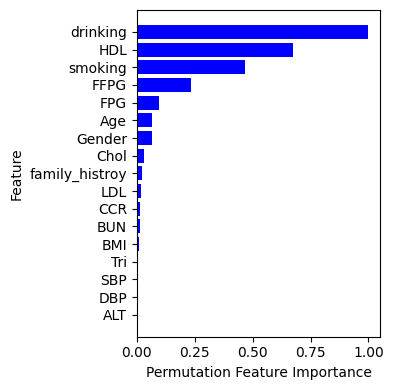

In [40]:
# 画图
plt.figure(figsize=(4, 4))  # 改变图形大小，使其适应竖向显示
plt.barh(sorted_feature_importance_df['Feature'], sorted_feature_importance_df['Importance'], color='b')
plt.ylabel('Feature')
plt.xlabel('Permutation Feature Importance')
# plt.gca().invert_yaxis()  # 反转y轴，使重要性最高的特征位于顶部
plt.tight_layout()

# 保存图像为300 dpi的EPS格式
plt.savefig('Permutation_importance_diabetes_nn_normalized.eps', format='eps', dpi=300)

# 显示图像
plt.show()

In [41]:
import time
s = time.time()
import shap

lgbexplainer = shap.SamplingExplainer(model.predict,x_test)
SamplingExplainer = lgbexplainer.shap_values(x_test)

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 481us/step


  0%|          | 0/861 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 259us/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 380us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 814us/step
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 285us/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 594us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 228us/step
3/3 ━━━━━

  0%|          | 1/861 [00:01<18:00,  1.26s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 272us/step
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 448us/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 283us/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 478us/step
199/199 ━━━━━━━━━━━━━━━━━━━━ 0s 206us/step
5/5 ━━━━━━━━━━━

...

100%|█████████▉| 859/861 [18:03<00:02,  1.28s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 373us/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 641us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 335us/step
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 400us/step
288/288 ━━━━━━━━━━━━━━━━━━━━ 0s 196us/step
8/8 ━━━━━━━━━━

100%|█████████▉| 860/861 [18:04<00:01,  1.28s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
91/91 ━━━━━━━━━━━━━━━━━━━━ 0s 238us/step
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 382us/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 405us/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 849us/step
201/201 ━━━━━━━━━━━━━━━━━━━━ 0s 204us/step
3/3 ━━━━━━━━━━━

100%|██████████| 861/861 [18:06<00:00,  1.26s/it]


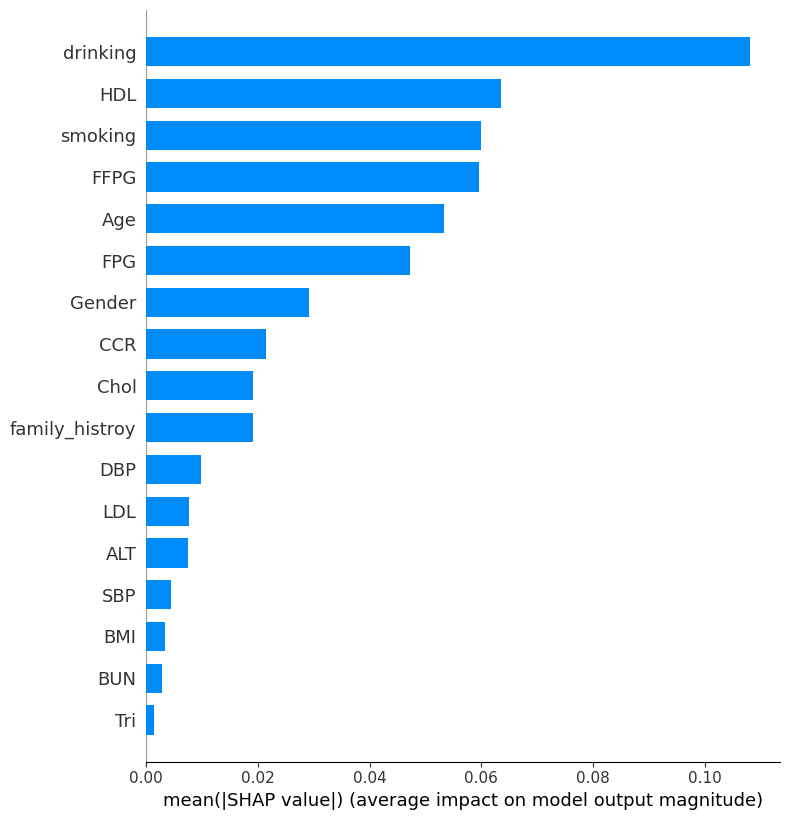

In [42]:
shap.summary_plot(SamplingExplainer, x_test, plot_type="bar", show=False, feature_names=feature_names)

In [43]:
e = time.time()
e-s

1086.3420538902283

In [71]:
# Extract and display the SHAP values for each feature
shap_df = pd.DataFrame(SamplingExplainer, columns=original_X.columns)
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)
shap_values_per_feature_sorted

Tri               0.001370
BUN               0.002750
BMI               0.003318
SBP               0.004405
ALT               0.007496
LDL               0.007615
DBP               0.009857
family_histroy    0.019065
Chol              0.019203
CCR               0.021400
Gender            0.029208
FPG               0.047191
Age               0.053221
FFPG              0.059621
smoking           0.060005
HDL               0.063581
drinking          0.108044
dtype: float64

In [72]:
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=True)
shap_values_per_feature_normalized

Tri               0.000000
BUN               0.012936
BMI               0.018262
SBP               0.028448
ALT               0.057423
LDL               0.058544
DBP               0.079558
family_histroy    0.165873
Chol              0.167165
CCR               0.187768
Gender            0.260961
FPG               0.429538
Age               0.486065
FFPG              0.546067
smoking           0.549665
HDL               0.583186
drinking          1.000000
dtype: float64

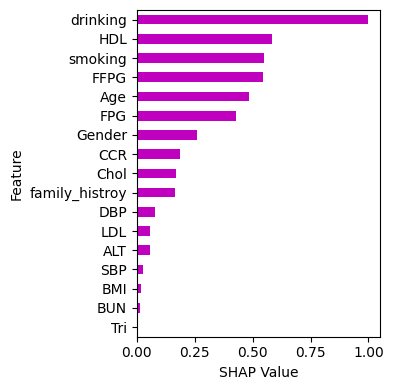

In [73]:
plt.figure(figsize=(4, 4))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized.plot(kind='barh', color='m')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('Samplingshap_life_diabetes_normalized.eps', format='eps', dpi=300)

plt.show()

In [47]:
import time
s = time.time()
kernel = shap.KernelExplainer(model.predict,x_test)
KernelExplainer = kernel.shap_values(x_test)

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 400us/step


Using 861 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
  0%|          | 0/861 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
56019/56019 ━━━━━━━━━━━━━━━━━━━━ 10s 177us/step


  0%|          | 1/861 [00:18<4:18:34, 18.04s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
56019/56019 ━━━━━━━━━━━━━━━━━━━━ 10s 178us/step


...

100%|█████████▉| 859/861 [3:45:49<00:30, 15.28s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
56019/56019 ━━━━━━━━━━━━━━━━━━━━ 10s 174us/step


100%|█████████▉| 860/861 [3:46:05<00:15, 15.30s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
56019/56019 ━━━━━━━━━━━━━━━━━━━━ 10s 174us/step


100%|██████████| 861/861 [3:46:20<00:00, 15.77s/it]


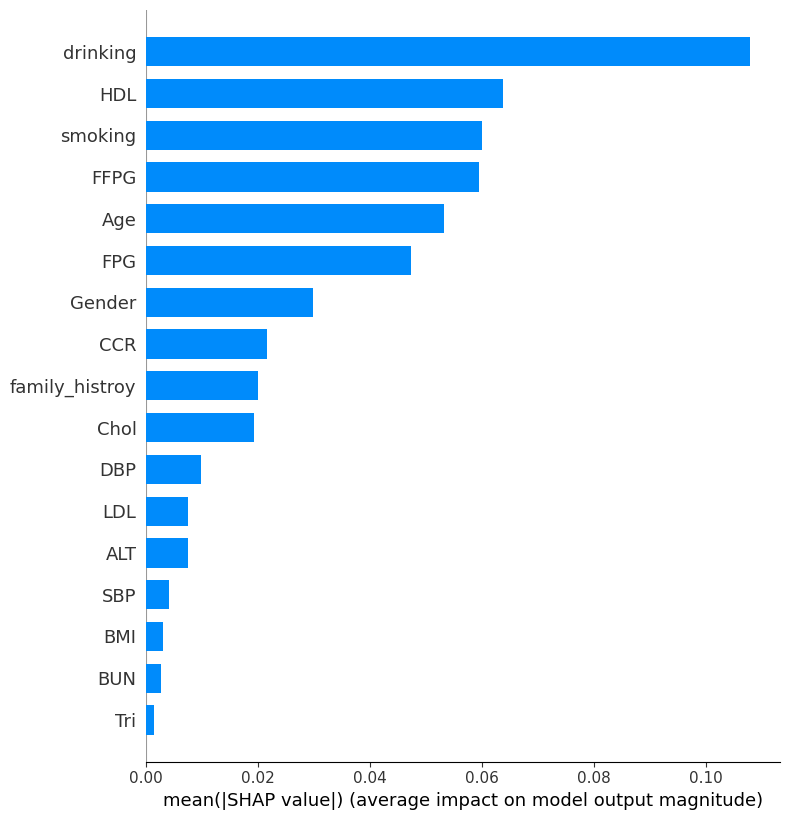

In [63]:
shap.summary_plot(KernelExplainer[:, :, 0], x_test, plot_type="bar", show=False, feature_names=original_X.columns.tolist())

In [50]:
KernelExplainer

array([[[-0.04389888],
        [ 0.01339813],
        [-0.00139089],
        ...,
        [-0.01152501],
        [-0.13520315],
        [-0.00782443]],

       [[-0.06070402],
        [-0.02493952],
        [-0.00120112],
        ...,
        [-0.04169139],
        [-0.07119106],
        [-0.00574695]],

       [[-0.06367165],
        [-0.03868076],
        [-0.00389616],
        ...,
        [-0.04882042],
        [-0.06532762],
        [-0.00863591]],

       ...,

       [[-0.07052587],
        [-0.02539059],
        [-0.00600779],
        ...,
        [-0.04750401],
        [-0.06718206],
        [-0.00577093]],

       [[-0.02779247],
        [ 0.0154045 ],
        [-0.00056009],
        ...,
        [-0.01227245],
        [-0.13776954],
        [-0.00935714]],

       [[-0.05889909],
        [-0.02811574],
        [-0.00359167],
        ...,
        [-0.04737195],
        [-0.06891158],
        [-0.00690371]]])

In [ ]:
e = time.time()
e-s

In [67]:
shap_df = pd.DataFrame(KernelExplainer[:, :, 0], columns=original_X.columns)


In [68]:
# Extract and display the SHAP values for each feature
shap_values_per_feature = shap_df.abs().mean()  # Calculate the average absolute SHAP value per feature

# Sort SHAP values from largest to smallest
shap_values_per_feature_sorted = shap_values_per_feature.sort_values(ascending=True)
shap_values_per_feature_sorted

Tri               0.001396
BUN               0.002593
BMI               0.003056
SBP               0.004158
ALT               0.007429
LDL               0.007515
DBP               0.009823
Chol              0.019170
family_histroy    0.020029
CCR               0.021560
Gender            0.029727
FPG               0.047291
Age               0.053261
FFPG              0.059400
smoking           0.059900
HDL               0.063663
drinking          0.107832
dtype: float64

In [69]:
shap_values_per_feature_normalized = (shap_values_per_feature - shap_values_per_feature.min()) / (shap_values_per_feature.max() - shap_values_per_feature.min())
shap_values_per_feature_normalized = shap_values_per_feature_normalized.sort_values(ascending=True)
shap_values_per_feature_normalized

Tri               0.000000
BUN               0.011243
BMI               0.015591
SBP               0.025951
ALT               0.056682
LDL               0.057491
DBP               0.079173
Chol              0.166993
family_histroy    0.175065
CCR               0.189442
Gender            0.266178
FPG               0.431195
Age               0.487285
FFPG              0.544969
smoking           0.549659
HDL               0.585016
drinking          1.000000
dtype: float64

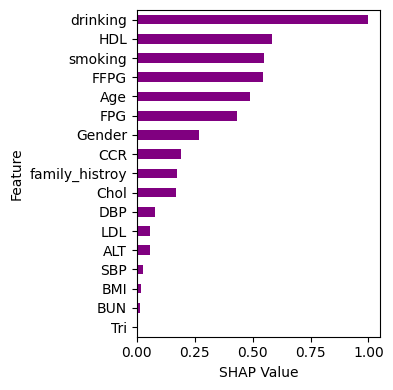

In [70]:
plt.figure(figsize=(4, 4))
# colors = plt.cm.viridis(range(len(sorted_feature_importance_df)))

# colors = plt.color_palette("c", len(shap_values_per_feature_sorted))

# Plot the sorted SHAP values for each feature vertically
bar_plot = shap_values_per_feature_normalized.plot(kind='barh', color='purple')
# plt.title('SHAP Values for H1N1 Vaccine Features', fontsize=14)
plt.xlabel('SHAP Value')
plt.ylabel('Feature')

# # Annotate the bars with SHAP values
# for i, value in enumerate(shap_values_per_feature_sorted):
#     bar_plot.text(value + 0.01, i, f'{value:.4f}', ha='left', va='center', fontsize=8)

plt.tight_layout()  # Adjusts subplot parameters to give specified padding

plt.savefig('Kernelshap_diabetes_nn_normalized.eps', format='eps', dpi=300)

plt.show()